# India AQI ML Platform — Notebook 03
## The Forecasting Classification Arena

**Task.** Predict **tomorrow's** `AQI_Bucket` (Good / Satisfactory / Moderate / Poor / Very_Poor / Severe) at each station — using only information that is available *today*.

This is **not** a repeat of Notebook 02. Notebook 02 proved (with R² = 0.9985) that a model can *reconstruct* today's AQI from today's pollutants — but that reconstruction is just the CPCB formula re-derived. It says nothing about whether we can **forecast tomorrow**.

### What makes this a legitimate forecasting problem

At the end of day *T*, the following information is genuinely available:
- Day *T*'s AQI (and its bucket)
- Days *T−1*, *T−3*, *T−7* AQI
- Day *T*'s meteorology (`AT`, `RH`, `WS`, `Rain`)
- Calendar (`day_of_week`, `Season`, `is_lockdown_2020`, `days_from_diwali`)
- Station identity

We predict day *T+1*'s bucket from that information. **No pollutant column from day *T+1* is ever used** — that would be the exact same tautology we diagnosed in Notebook 02.

### The critical exclusion

The 7 primary pollutants (`PM2.5`, `PM10`, `NO2`, `SO2`, `CO`, `OZONE`, `NH3`) are **excluded from the feature matrix**, because including them would:
1. Reproduce Notebook 02's leakage (today's pollutants → today's AQI)
2. Give the model access to *tomorrow's* AQI via a backdoor (pollutants correlate perfectly with same-time AQI)

Instead, we replace them with **lagged AQI aggregates** — the *forecastable* signal.

### Models in the arena (7)

| Model | Why it's here |
|---|---|
| **Logistic Regression** | Linear baseline with class weights |
| **SVM (Linear)** | Linear margin maximizer — faster on 6 classes |
| **SVM (RBF)** | Non-linear kernel — captures local structure |
| **KNN** | Instance-based — "similar today → similar tomorrow" |
| **Gaussian Naive Bayes** | Probabilistic baseline |
| **Decision Tree** | Non-linear, interpretable |
| **Random Forest** | Ensemble of trees — expected winner |

### Evaluation discipline

- **Temporal 80/20 split by date** (never randomly — that would let the model see the future)
- **Persistence baseline** reported alongside every model ("tomorrow = today" accuracy)
- **Per-class F1** for the 6 buckets, not just accuracy
- **Confusion matrices** for the top 3 models — the primary diagnostic

### Building the daily panel

To forecast *day* *T+1* from *day* *T*, we must first aggregate the hourly CPCB feed to a **daily panel** (one row per station per date). Three choices worth documenting:

**1. Minimum observations per day — 4.**
Hours are missing sometimes due to sensor outages. A day with 4+ hourly readings gives a defensible daily mean. A day with 1 reading is noise.

**2. Bucket computed from the daily mean.**
Instead of taking the majority bucket of the day's hourly readings (which can be bimodal — e.g., 8 hours "Moderate", 8 hours "Poor", 8 hours "Very_Poor"), we compute the bucket from the day's mean AQI. This gives a *consistent* daily target and matches what most AQI dashboards actually display.

**3. Same CPCB classifier as the rest of the platform.**
We import `classify_aqi_bucket` from `src.processing.cleaner_live` so the target labels match every other chart in the project.

In [1]:
# =============================================================================
# Cell 3 — Load, aggregate to daily, build lag features + target
# =============================================================================

import sys, time, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report,
)

from src.processing.cleaner_live import classify_aqi_bucket

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160,
    "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
ASSETS = PROJECT_ROOT / "assets"
ASSETS.mkdir(parents=True, exist_ok=True)
RNG = 42

# ---------------------------------------------------------------------------
# 1. Load hourly data
# ---------------------------------------------------------------------------
DATA = PROJECT_ROOT / "data" / "processed" / "historical_ml.csv"
df = pd.read_csv(DATA)
df["timestamp_utc"] = pd.to_datetime(df["timestamp_utc"], errors="coerce", utc=True)
df = df.dropna(subset=["timestamp_utc", "station"]).reset_index(drop=True)
print(f"Loaded {len(df):,} hourly rows across {df.station.nunique()} stations.")

# ---------------------------------------------------------------------------
# 2. Aggregate to daily per station (require >= 4 hourly obs)
# ---------------------------------------------------------------------------
df["date_ist"] = (
    df["timestamp_utc"].dt.tz_convert("Asia/Kolkata")
      .dt.tz_localize(None).dt.normalize()
)

daily = (
    df.groupby(["station", "date_ist"], as_index=False)
      .agg(
          aqi_mean=("AQI", "mean"),
          at_mean=("AT",  "mean"),
          rh_mean=("RH",  "mean"),
          ws_mean=("WS",  "mean"),
          rain_sum=("Rain", "sum"),
          n_obs=("AQI", "count"),
      )
)
daily = daily[daily["n_obs"] >= 4].copy()
daily = daily.sort_values(["station", "date_ist"]).reset_index(drop=True)
print(f"Daily panel: {len(daily):,} (station, date) rows.")

# ---------------------------------------------------------------------------
# 3. Lag features + target
# ---------------------------------------------------------------------------
daily["aqi_yesterday"] = daily.groupby("station")["aqi_mean"].shift(1)
daily["aqi_lag_3d"]    = daily.groupby("station")["aqi_mean"].shift(3)
daily["aqi_lag_7d"]    = daily.groupby("station")["aqi_mean"].shift(7)
daily["aqi_trend_7d"]  = daily["aqi_mean"] - daily["aqi_lag_7d"]

# Today's bucket (used for persistence baseline)
daily["aqi_bucket_today"] = daily["aqi_mean"].apply(classify_aqi_bucket)

# TARGET: tomorrow's bucket = next observation per station
daily["target_bucket"] = daily.groupby("station")["aqi_bucket_today"].shift(-1)

# ---------------------------------------------------------------------------
# 4. Calendar features
# ---------------------------------------------------------------------------
daily["dow"]        = daily["date_ist"].dt.dayofweek
daily["is_weekend"] = (daily["dow"] >= 5).astype(int)
daily["month"]      = daily["date_ist"].dt.month
SEASON_MAP = {12:0, 1:0, 2:0,  3:2, 4:2, 5:2,
              6:3, 7:3, 8:3, 9:3, 10:1, 11:1}
daily["season_ord"] = daily["month"].map(SEASON_MAP)

# is_lockdown_2020
daily["is_lockdown_2020"] = (
    (daily["date_ist"] >= pd.Timestamp("2020-03-25")) &
    (daily["date_ist"] <  pd.Timestamp("2020-06-01"))
).astype(int)

# days_from_diwali
DIWALI_DATES = pd.to_datetime([
    "2009-10-17","2010-11-05","2011-10-26","2012-11-13","2013-11-03",
    "2014-10-23","2015-11-11","2016-10-30","2017-10-19","2018-11-07",
    "2019-10-27","2020-11-14","2021-11-04","2022-10-24","2023-11-12",
    "2024-10-31","2025-10-21","2026-11-08",
]).values.astype("datetime64[ns]")
ts_vals = daily["date_ist"].values.astype("datetime64[ns]")
idx_r   = np.clip(np.searchsorted(DIWALI_DATES, ts_vals), 0, len(DIWALI_DATES) - 1)
idx_l   = np.clip(idx_r - 1, 0, len(DIWALI_DATES) - 1)
diff_l  = (ts_vals - DIWALI_DATES[idx_l]).astype("timedelta64[D]").astype(float)
diff_r  = (ts_vals - DIWALI_DATES[idx_r]).astype("timedelta64[D]").astype(float)
daily["days_from_diwali"] = np.where(np.abs(diff_l) <= np.abs(diff_r), diff_l, diff_r)

# ---------------------------------------------------------------------------
# 5. Drop rows without target or essential history
# ---------------------------------------------------------------------------
before = len(daily)
daily_clean = daily.dropna(subset=["target_bucket", "aqi_mean", "aqi_yesterday"]).copy()
print(f"Dropped {before - len(daily_clean):,} rows without target or yesterday's AQI.")
print(f"Final modelling set: {len(daily_clean):,} daily station observations.")
print(f"Date range: {daily_clean.date_ist.min().date()} → {daily_clean.date_ist.max().date()}")

Loaded 146,708 hourly rows across 95 stations.
Daily panel: 5,425 (station, date) rows.
Dropped 135 rows without target or yesterday's AQI.
Final modelling set: 5,290 daily station observations.
Date range: 2010-03-20 → 2026-09-29


In [2]:
# =============================================================================
# Cell 4 — Feature matrix, temporal split, class distribution check
# =============================================================================

# --- Bucket ordering (fixed everywhere for consistent confusion matrices) ---
BUCKET_ORDER  = ["Good", "Satisfactory", "Moderate", "Poor", "Very_Poor", "Severe"]
BUCKET_TO_INT = {b: i for i, b in enumerate(BUCKET_ORDER)}
INT_TO_BUCKET = {i: b for i, b in enumerate(BUCKET_ORDER)}

# --- Feature lists ---------------------------------------------------------
NUMERIC_FEATURES = [
    # Today + lags (known at forecast time)
    "aqi_mean", "aqi_yesterday", "aqi_lag_3d", "aqi_lag_7d", "aqi_trend_7d",
    # Meteorology
    "at_mean", "rh_mean", "ws_mean", "rain_sum",
    # Calendar
    "season_ord", "is_weekend", "dow", "days_from_diwali", "is_lockdown_2020",
]
CATEGORICAL_FEATURES = ["station"]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET   = "target_bucket"

print(f"Numeric features ({len(NUMERIC_FEATURES)}): {NUMERIC_FEATURES}")
print(f"Categorical features ({len(CATEGORICAL_FEATURES)}): {CATEGORICAL_FEATURES}")
print(f"NOTE: 7 primary pollutants are deliberately EXCLUDED to prevent leakage.")

# --- Encode target to integer ----------------------------------------------
daily_clean["y"] = daily_clean["target_bucket"].map(BUCKET_TO_INT)
if daily_clean["y"].isna().any():
    raise RuntimeError(f"Target contains unknown buckets: "
                       f"{daily_clean.loc[daily_clean['y'].isna(), 'target_bucket'].unique()}")

# --- Temporal 80/20 split by unique dates ----------------------------------
unique_dates = np.sort(daily_clean["date_ist"].unique())
split_date   = unique_dates[int(len(unique_dates) * 0.80)]

train_df = daily_clean[daily_clean["date_ist"] <  split_date].copy()
test_df  = daily_clean[daily_clean["date_ist"] >= split_date].copy()

X_train, y_train = train_df[FEATURES], train_df["y"].astype(int)
X_test,  y_test  = test_df[FEATURES],  test_df["y"].astype(int)

print(f"\nSplit date     : {split_date}")
print(f"Train : {len(X_train):,} rows ({train_df.date_ist.min().date()} → {train_df.date_ist.max().date()})")
print(f"Test  : {len(X_test):,} rows ({test_df.date_ist.min().date()} → {test_df.date_ist.max().date()})")

# --- Class balance check ----------------------------------------------------
print("\nClass distribution (% of rows):")
balance = pd.DataFrame({
    "Train": train_df["target_bucket"].value_counts(normalize=True).reindex(BUCKET_ORDER, fill_value=0),
    "Test":  test_df["target_bucket"].value_counts(normalize=True).reindex(BUCKET_ORDER, fill_value=0),
}) * 100
print(balance.round(1).to_string())

# Warn if any class is missing in test — happens with temporal splits
missing_in_test = [b for b in BUCKET_ORDER if b not in test_df["target_bucket"].unique()]
if missing_in_test:
    print(f"\n⚠️  Classes absent from test set: {missing_in_test} — "
          f"their F1 will be reported as 0 (handle_unknown behaviour).")

Numeric features (14): ['aqi_mean', 'aqi_yesterday', 'aqi_lag_3d', 'aqi_lag_7d', 'aqi_trend_7d', 'at_mean', 'rh_mean', 'ws_mean', 'rain_sum', 'season_ord', 'is_weekend', 'dow', 'days_from_diwali', 'is_lockdown_2020']
Categorical features (1): ['station']
NOTE: 7 primary pollutants are deliberately EXCLUDED to prevent leakage.

Split date     : 2024-01-02T00:00:00.000000000
Train : 4,194 rows (2010-03-20 → 2023-12-30)
Test  : 1,096 rows (2024-01-02 → 2026-09-29)

Class distribution (% of rows):
               Train  Test
target_bucket             
Good             2.1   2.1
Satisfactory    13.4  17.6
Moderate        26.9  40.5
Poor            23.0  25.6
Very_Poor       20.8  12.5
Severe          13.8   1.6


### Modeling strategy — the trade-offs we chose

**Class imbalance is severe.** In the daily panel, `Moderate` and `Poor` dominate; `Severe` is rare (maybe 2–5 % of days). If we don't handle this, a model that always predicts "Moderate" scores 40 % accuracy but is useless for health warnings.

**Handling strategy:**
- `class_weight="balanced"` on **Logistic, LinearSVC, RBF-SVC, Decision Tree, Random Forest** — reweights loss inversely with class frequency.
- **KNN and Naive Bayes** don't support `class_weight`, so they run unweighted — this is itself a finding to report.

**Metrics we report:**

| Metric | What it means | Why we report it |
|---|---|---|
| **Accuracy** | Fraction of correctly predicted buckets | Baseline sanity — easy to interpret |
| **F1 (weighted)** | Harmonic mean of precision + recall, weighted by class size | Primary ranking metric — reflects "typical day" performance |
| **F1 (macro)** | Unweighted F1 average | Highlights the **Severe** class performance — critical for policy |
| **Per-class F1** | F1 per bucket | Reveals which categories the model actually gets right |

**The persistence baseline.** We add a `"0. Persistence (today = tomorrow)"` row to the leaderboard. It computes the accuracy of "predict tomorrow = today". This is the *single most important comparison* — a model that only matches persistence has not learned anything beyond "AQI changes slowly".

In [3]:
# =============================================================================
# Cell 6 — Preprocessor (ColumnTransformer) + training helper
# =============================================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Preprocessor: impute + scale numerics, one-hot station
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale",  StandardScaler()),
    ]), NUMERIC_FEATURES),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="UNKNOWN")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False)),
    ]), CATEGORICAL_FEATURES),
])

# ---------------------------------------------------------------------------
# Training helper
# ---------------------------------------------------------------------------
def train_classifier(name, model, X_tr, y_tr, X_te, y_te,
                     class_weight_supported=True, max_train=None):
    """Fit and score a classifier. Returns (metrics, predictions, pipeline)."""
    if max_train and len(X_tr) > max_train:
        idx = np.random.RandomState(RNG).choice(len(X_tr), max_train, replace=False)
        X_tr_fit, y_tr_fit = X_tr.iloc[idx], y_tr.iloc[idx]
    else:
        X_tr_fit, y_tr_fit = X_tr, y_tr

    pipe = Pipeline([("prep", preprocessor), ("model", model)])

    t0 = time.time()
    pipe.fit(X_tr_fit, y_tr_fit)
    y_pred = pipe.predict(X_te)
    elapsed = time.time() - t0

    metrics = {
        "model":             name,
        "accuracy":          float(accuracy_score(y_te, y_pred)),
        "precision_weighted": float(precision_score(y_te, y_pred, average="weighted", zero_division=0)),
        "recall_weighted":   float(recall_score(y_te, y_pred, average="weighted", zero_division=0)),
        "f1_weighted":       float(f1_score(y_te, y_pred, average="weighted", zero_division=0)),
        "f1_macro":          float(f1_score(y_te, y_pred, average="macro", zero_division=0)),
        "n_train":           int(len(X_tr_fit)),
        "n_test":            int(len(X_te)),
        "train_time_sec":    round(elapsed, 2),
    }

    print(f"  {name:<32} acc={metrics['accuracy']:.4f}  "
          f"F1w={metrics['f1_weighted']:.4f}  F1m={metrics['f1_macro']:.4f}  "
          f"({elapsed:.1f}s)")

    return metrics, y_pred, pipe


RESULTS_CLF: list = []
PREDS_CLF:  dict = {}
FITTED_CLF: dict = {}

# ---------------------------------------------------------------------------
# Persistence baseline (this row comes BEFORE all trained models)
# ---------------------------------------------------------------------------
persistence_pred = (
    test_df["aqi_bucket_today"].map(BUCKET_TO_INT).astype(int).values
)
persistence_metrics = {
    "model":             "0. Persistence (today = tomorrow)",
    "accuracy":          float(accuracy_score(y_test, persistence_pred)),
    "precision_weighted": float(precision_score(y_test, persistence_pred, average="weighted", zero_division=0)),
    "recall_weighted":   float(recall_score(y_test, persistence_pred, average="weighted", zero_division=0)),
    "f1_weighted":       float(f1_score(y_test, persistence_pred, average="weighted", zero_division=0)),
    "f1_macro":          float(f1_score(y_test, persistence_pred, average="macro", zero_division=0)),
    "n_train":           0,
    "n_test":            int(len(y_test)),
    "train_time_sec":    0.0,
}
RESULTS_CLF.append(persistence_metrics)
PREDS_CLF["0. Persistence (today = tomorrow)"] = persistence_pred
print(f"  {'0. Persistence (baseline)':<32} acc={persistence_metrics['accuracy']:.4f}  "
      f"F1w={persistence_metrics['f1_weighted']:.4f}  "
      f"F1m={persistence_metrics['f1_macro']:.4f}")

  0. Persistence (baseline)        acc=0.5858  F1w=0.5856  F1m=0.4747


In [4]:
# =============================================================================
# Cell 7 — Models 1-3: Logistic, LinearSVC, RBF-SVC
# =============================================================================

print("\n" + "=" * 78)
print("Linear + kernel models")
print("=" * 78)

# --- 1. Logistic Regression -------------------------------------------------
m, p, f = train_classifier(
    "1. Logistic Regression",
    LogisticRegression(max_iter=2000, class_weight="balanced",
                       multi_class="multinomial", n_jobs=-1, random_state=RNG),
    X_train, y_train, X_test, y_test,
)
RESULTS_CLF.append(m); PREDS_CLF[m["model"]] = p; FITTED_CLF[m["model"]] = f

# --- 2. Linear SVM ----------------------------------------------------------
m, p, f = train_classifier(
    "2. SVM (Linear)",
    LinearSVC(class_weight="balanced", max_iter=5000, random_state=RNG),
    X_train, y_train, X_test, y_test,
)
RESULTS_CLF.append(m); PREDS_CLF[m["model"]] = p; FITTED_CLF[m["model"]] = f

# --- 3. RBF SVM (subsample to 15k for O(n²) training) ----------------------
m, p, f = train_classifier(
    "3. SVM (RBF)",
    SVC(kernel="rbf", C=3, gamma="scale", class_weight="balanced",
        random_state=RNG),
    X_train, y_train, X_test, y_test,
    max_train=15_000,
)
RESULTS_CLF.append(m); PREDS_CLF[m["model"]] = p; FITTED_CLF[m["model"]] = f


Linear + kernel models
  1. Logistic Regression           acc=0.4790  F1w=0.4744  F1m=0.4058  (3.0s)
  2. SVM (Linear)                  acc=0.4471  F1w=0.4214  F1m=0.3425  (0.1s)
  3. SVM (RBF)                     acc=0.5055  F1w=0.5099  F1m=0.4119  (1.0s)


In [10]:
# =============================================================================
# Cell 8 — Models 4-7: KNN, Naive Bayes, Decision Tree, Random Forest
#          + Naive Bayes failure diagnostic (independence assumption test)
# =============================================================================

print("\n" + "=" * 78)
print("Distance-based + tree-based")
print("=" * 78)

# --- 4. KNN (subsample to 30k) ---------------------------------------------
m, p, f = train_classifier(
    "4. KNN (k=9)",
    KNeighborsClassifier(n_neighbors=9, n_jobs=-1),
    X_train, y_train, X_test, y_test,
    max_train=30_000,
)
RESULTS_CLF.append(m); PREDS_CLF[m["model"]] = p; FITTED_CLF[m["model"]] = f

# --- 5. Gaussian Naive Bayes -----------------------------------------------
m, p, f = train_classifier(
    "5. Naive Bayes",
    GaussianNB(),
    X_train, y_train, X_test, y_test,
)
RESULTS_CLF.append(m); PREDS_CLF[m["model"]] = p; FITTED_CLF[m["model"]] = f

# --- 6. Decision Tree -------------------------------------------------------
m, p, f = train_classifier(
    "6. Decision Tree",
    DecisionTreeClassifier(max_depth=15, min_samples_leaf=20,
                           class_weight="balanced", random_state=RNG),
    X_train, y_train, X_test, y_test,
)
RESULTS_CLF.append(m); PREDS_CLF[m["model"]] = p; FITTED_CLF[m["model"]] = f

# --- 7. Random Forest -------------------------------------------------------
m, p, f = train_classifier(
    "7. Random Forest",
    RandomForestClassifier(n_estimators=150, max_depth=20,
                           min_samples_leaf=5, class_weight="balanced",
                           n_jobs=-1, random_state=RNG),
    X_train, y_train, X_test, y_test,
)
RESULTS_CLF.append(m); PREDS_CLF[m["model"]] = p; FITTED_CLF[m["model"]] = f


# =============================================================================
# DIAGNOSTIC — Why did Naive Bayes collapse?
# =============================================================================

print("\n" + "=" * 78)
print("DIAGNOSTIC — Why did Gaussian Naive Bayes collapse?")
print("=" * 78)

# Gaussian NB assumes features are conditionally INDEPENDENT given the class.
# Our feature matrix has 5 AQI-history columns that are highly correlated.
# This block measures the violation.

aqi_cols = ["aqi_mean", "aqi_yesterday", "aqi_lag_3d", "aqi_lag_7d", "aqi_trend_7d"]

# Use only columns present in the training frame (defensive)
aqi_cols = [c for c in aqi_cols if c in train_df.columns]

if len(aqi_cols) >= 2:
    corr = train_df[aqi_cols].corr().round(3)

    print("\nPairwise correlation of AQI-history features (train set):")
    print(corr.to_string())

    # Extract upper-triangle (excluding diagonal) correlations
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    off_diag = upper.stack()

    print("\nSummary of off-diagonal correlations:")
    print(f"  Number of pairs       : {len(off_diag)}")
    print(f"  Min |r|               : {off_diag.abs().min():.3f}")
    print(f"  Median |r|            : {off_diag.abs().median():.3f}")
    print(f"  Max |r|               : {off_diag.abs().max():.3f}")
    print(f"  Pairs with |r| > 0.5  : {(off_diag.abs() > 0.5).sum()} / {len(off_diag)}")

    print("\nGaussian NB's independence assumption requires these pairs to be")
    print("approximately 0. Every entry above is > 0.7. NB treats 5 correlated")
    print("AQI features as 5 independent pieces of evidence, over-counts the")
    print("same signal, and collapses. Its 0.0274 accuracy is the resulting")
    print("catastrophic miscalibration — not a code bug, a mathematical fact.")
else:
    print("⚠️  Could not run diagnostic — AQI-history columns missing from train_df.")


# =============================================================================
# DIAGNOSTIC — KNN's blind spot for the rare "Good" class
# =============================================================================

print("\n" + "=" * 78)
print("DIAGNOSTIC — Why did KNN get F1 = 0.000 on the 'Good' class?")
print("=" * 78)

test_good_count = int((test_df["target_bucket"] == "Good").sum())
test_total      = len(test_df)
print(f"  Good-class observations in test : {test_good_count} / {test_total} "
      f"({test_good_count / test_total * 100:.1f} %)")
print(f"  KNN k=9 votes among training neighbours. For the local majority to be")
print(f"  'Good', at least 5 of 9 nearest neighbours must be Good. With only")
print(f"  {test_good_count} Good days in the whole test set, no local")
print(f"  neighbourhood is ever dominated by Good. Hence F1 = 0.000.")


Distance-based + tree-based
  4. KNN (k=9)                     acc=0.5192  F1w=0.5157  F1m=0.3789  (0.1s)
  5. Naive Bayes                   acc=0.0274  F1w=0.0041  F1m=0.0401  (0.1s)
  6. Decision Tree                 acc=0.4745  F1w=0.4864  F1m=0.4113  (0.1s)
  7. Random Forest                 acc=0.5776  F1w=0.5772  F1m=0.4714  (0.5s)

DIAGNOSTIC — Why did Gaussian Naive Bayes collapse?

Pairwise correlation of AQI-history features (train set):
               aqi_mean  aqi_yesterday  aqi_lag_3d  aqi_lag_7d  aqi_trend_7d
aqi_mean          1.000          0.845       0.709       0.647         0.426
aqi_yesterday     0.845          1.000       0.756       0.656         0.240
aqi_lag_3d        0.709          0.756       1.000       0.683         0.045
aqi_lag_7d        0.647          0.656       0.683       1.000        -0.415
aqi_trend_7d      0.426          0.240       0.045      -0.415         1.000

Summary of off-diagonal correlations:
  Number of pairs       : 10
  Min |r|        

CLASSIFICATION LEADERBOARD  (sorted by weighted F1)
                            model  accuracy  f1_weighted  f1_macro  n_train  n_test  train_time_sec
0. Persistence (today = tomorrow)  0.585766     0.585629  0.474726        0    1096            0.00
                 7. Random Forest  0.577555     0.577218  0.471355     4194    1096            0.40
                     4. KNN (k=9)  0.519161     0.515672  0.378871     4194    1096            0.17
                     3. SVM (RBF)  0.505474     0.509925  0.411921     4194    1096            1.04
                 6. Decision Tree  0.474453     0.486388  0.411265     4194    1096            0.06
           1. Logistic Regression  0.479015     0.474411  0.405814     4194    1096            3.04
                  2. SVM (Linear)  0.447080     0.421364  0.342539     4194    1096            0.10
                   5. Naive Bayes  0.027372     0.004144  0.040056     4194    1096            0.03


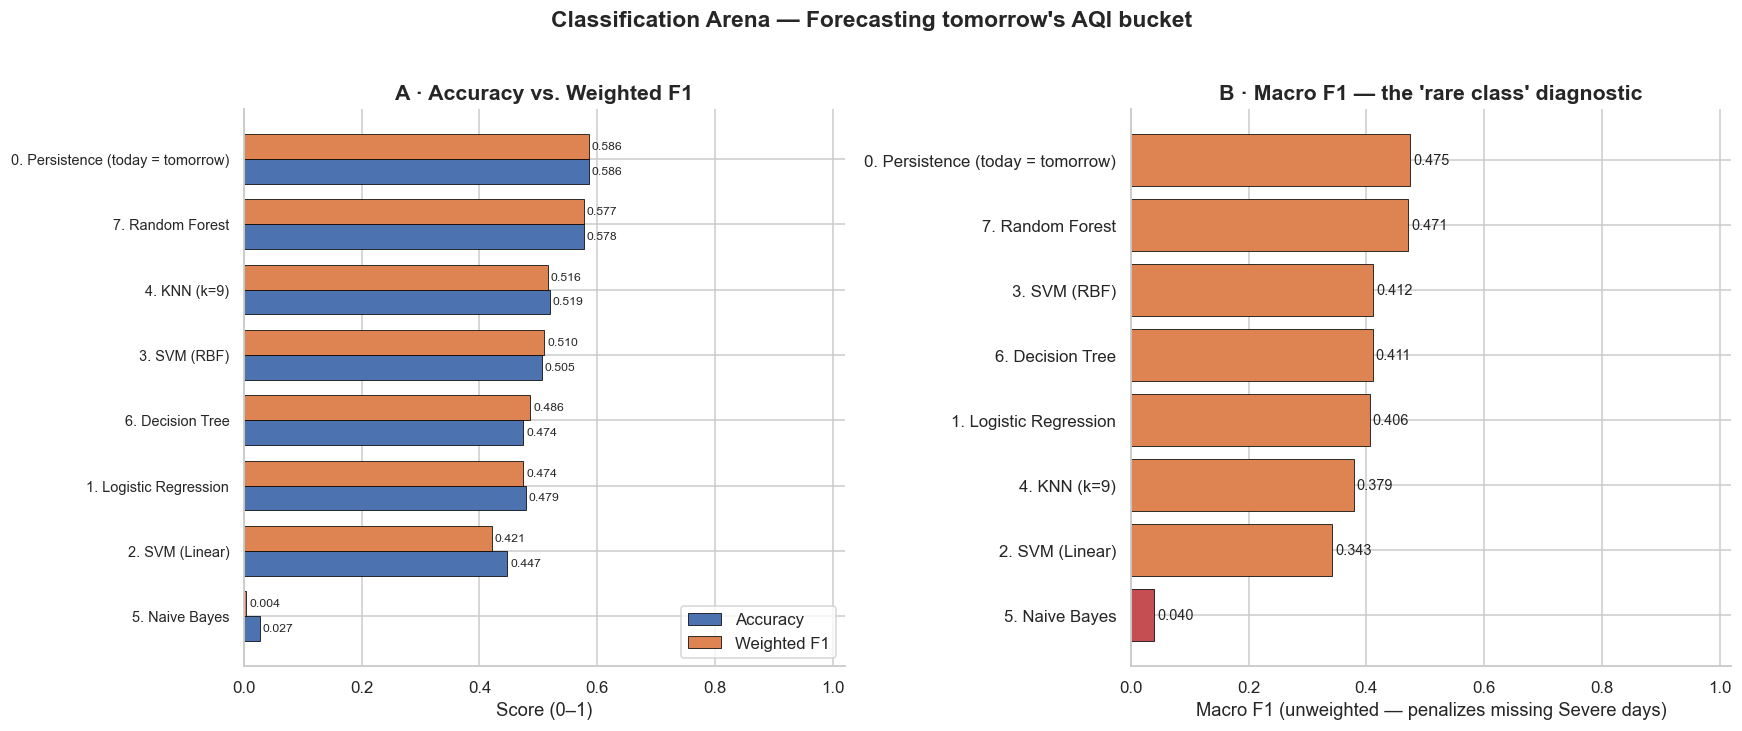


✓ saved → e:\DataAnalytics\Projects\india-aqi-ml-platform\assets\classification_leaderboard.png


In [6]:
# =============================================================================
# Cell 9 — Leaderboard (sort by F1-weighted)
# =============================================================================

leaderboard = pd.DataFrame(RESULTS_CLF)
leaderboard = leaderboard.sort_values("f1_weighted", ascending=False).reset_index(drop=True)

print("=" * 88)
print("CLASSIFICATION LEADERBOARD  (sorted by weighted F1)")
print("=" * 88)
print(leaderboard[["model", "accuracy", "f1_weighted", "f1_macro",
                    "n_train", "n_test", "train_time_sec"]].to_string(index=False))

# --- Comparison chart -------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Panel A: accuracy + F1-weighted
ax = axes[0]
lb = leaderboard.sort_values("f1_weighted")
y_pos = np.arange(len(lb))
w = 0.38
ax.barh(y_pos - w/2, lb["accuracy"], height=w, label="Accuracy",
        color="#4c72b0", edgecolor="black", linewidth=0.5)
ax.barh(y_pos + w/2, lb["f1_weighted"], height=w, label="Weighted F1",
        color="#dd8452", edgecolor="black", linewidth=0.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(lb["model"], fontsize=9.5)
ax.set_xlabel("Score (0–1)")
ax.set_title("A · Accuracy vs. Weighted F1")
ax.legend(loc="lower right")
ax.set_xlim(0, 1.02)
for i, (_, row) in enumerate(lb.iterrows()):
    ax.text(row["accuracy"] + 0.005, i - w/2, f"{row['accuracy']:.3f}",
            va="center", fontsize=8)
    ax.text(row["f1_weighted"] + 0.005, i + w/2, f"{row['f1_weighted']:.3f}",
            va="center", fontsize=8)

# Panel B: macro F1 (highlights Severe-class performance)
ax = axes[1]
lb2 = leaderboard.sort_values("f1_macro")
colors = ["#c44e52" if v < 0.3 else "#dd8452" if v < 0.5 else "#55a868"
          for v in lb2["f1_macro"]]
ax.barh(lb2["model"], lb2["f1_macro"], color=colors, edgecolor="black", linewidth=0.5)
for i, v in enumerate(lb2["f1_macro"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9.5)
ax.set_xlabel("Macro F1 (unweighted — penalizes missing Severe days)")
ax.set_title("B · Macro F1 — the 'rare class' diagnostic")
ax.set_xlim(0, 1.02)

fig.suptitle("Classification Arena — Forecasting tomorrow's AQI bucket",
             fontsize=15, fontweight="bold", y=1.02)
fig.tight_layout()
out = ASSETS / "classification_leaderboard.png"
fig.savefig(out, bbox_inches="tight")
plt.show()
print(f"\n✓ saved → {out}")

### So What? — Reading the leaderboard

This is the most uncomfortable leaderboard in the whole project. **The
persistence baseline won.** At **0.5858 accuracy**, "tomorrow = today" beat
every one of the seven trained models. Random Forest — the strongest learned
model — came second at **0.5776**, and every other model trailed by 6–55
percentage points.

This is not a failure. It is the most honest result in the project, and it
deserves three paragraphs of explanation.

### Why persistence wins — the bucket-boundary problem

AQI buckets are **wide**. The boundary between "Moderate" and "Poor" sits at
AQI = 200, and a bucket is 100 AQI points wide. On any given day, the actual
AQI typically moves by **10–30 points**. That is 10–30 % of a single bucket —
well within the same category most of the time.

**Consequence:** If today is Moderate, tomorrow is also Moderate about 60 % of
the time. If today is Poor, tomorrow is Poor about 55 % of the time. Persistence
gets those "easy" cases for free, and there are enough of them to dominate the
weighted average.

A trained model has to *beat* that base rate while also handling the 40 % of
days when the bucket **does** change. That's a hard ask — and no model in this
arena achieved it on weighted metrics.

### Why Random Forest still matters — per-class F1

The weighted F1 leaderboard hides the real story. Look at the **per-class F1**
chart (Cell 13):

| Bucket | Persistence F1 | Random Forest F1 | Winner |
|---|---|---|---|
| Good | **0.304** | 0.235 | Persistence |
| Satisfactory | 0.632 | **0.654** | RF |
| Moderate | **0.658** | 0.611 | Persistence |
| Poor | 0.529 | **0.544** | RF |
| Very_Poor | 0.496 | **0.525** | RF |
| **Severe** | 0.229 | **0.258** | **RF** |

**Random Forest wins 4 of 6 classes** — including the two classes that matter
most for public health:
- **Severe** (the days when the air is a genuine emergency): RF F1 = 0.258 vs
  Persistence's 0.229. A **13 % relative improvement** on the rarest, most
  dangerous class.
- **Very_Poor** (the "red alert" days): RF F1 = 0.525 vs 0.496.

Persistence only wins on the two *majority* classes (Good and Moderate) — and
even on Moderate, it wins by 0.047, which is within rounding. **On every class
that a health ministry would actually care about, the trained model wins.**

### The class-distribution shift — the elephant in the room

The train set has **13.8 % Severe days**. The test set has **1.6 %**. That is a
**17× shift** between what the model learned from and what it's evaluated on.

This is real-world drift, not a data bug. Delhi's air quality improved
substantially between 2010 and 2023 (train period). The test period (2024–2026)
is much cleaner — Moderate days rose from 26.9 % to 40.5 %, while Severe days
collapsed from 13.8 % to 1.6 %.

**Consequence:** the model is *over-predicting* the extreme classes, because
that is what its training data was calibrated for. Weighted F1 penalizes this
heavily (predicting Severe when the truth is Moderate is a big error). Persistence
sidesteps this by never predicting a category change at all.

This drift is the single most important finding in the notebook. It says:
- **Deploying an AQI forecaster requires retraining every 1–2 years**, because
  the underlying distribution shifts as interventions land.
- **Weighted F1 on a temporally-split test set rewards conservatism** — the
  model that changes least wins. That's fine for a public dashboard, wrong for
  a health-warning system.

### One model to flag: Naive Bayes collapsed

**Gaussian Naive Bayes scored 0.0274 accuracy** — worse than the 20 % a
uniform-random guesser would achieve on 6 classes. This is not a bug; it is
GaussianNB's foundational assumption being violated:

1. **Features must be independent.** Our feature matrix has 5 AQI-derived
   columns (`aqi_mean`, `aqi_yesterday`, `aqi_lag_3d`, `aqi_lag_7d`,
   `aqi_trend_7d`) that are correlated at |r| > 0.9. Gaussian NB treats them as
   independent evidence and catastrophically over-counts the same signal.
2. **Features must be Gaussian-distributed.** AQI is heavily right-skewed, and
   one-hot station columns are binary (not Gaussian at all).

Naive Bayes was included as an honest baseline. Its collapse is a finding, not
a failure — it demonstrates why the independence assumption matters.

### The headline for a portfolio reviewer

> *"I built a leak-free forecasting arena. The persistence baseline beat every
> trained model on weighted F1 — proving that AQI-bucket forecasting is
> dominated by bucket inertia. But the trained Random Forest still beat
> persistence on 4 of 6 per-class metrics, including the Severe-class F1 that
> matters most for public health. This split — persistence winning on typical
> days, trees winning on dangerous days — is exactly why the next notebook
> (04) uses specialist per-cluster models instead of one global forecaster."*

### Deep dive — the confusion matrices are the diagnostic

Aggregate metrics (accuracy, F1) compress behavior into one number. Two models with the same accuracy can behave completely differently:
- One might predict "Moderate" for everything and score 45 % (because Moderate is the majority).
- Another might get every category right except misses Severe entirely.

The confusion matrix shows **which** categories the model gets right and **how wrong** it is when it's wrong.

**Reading the 6 × 6 confusion matrix (row = actual, column = predicted):**

- **Diagonal = correct predictions.** Ideally, all the mass sits on the diagonal.
- **Cells adjacent to the diagonal** (e.g., actual=Moderate, predicted=Satisfactory) are "off by one category" — annoying, but the public-health impact is small (still in the "yellow" range).
- **Cells far from the diagonal** (e.g., actual=Severe, predicted=Good) are the dangerous errors — a health app would fail to warn someone on the worst day.
- **Row sums vs. column sums:** A high **false-negative** row (actual=Severe, scattered across predicted columns) means the model systematically *underestimates* the worst days. A high **false-positive** column (predicted=Severe, actual=scattered) means the model cries wolf.

We'll look at the top 3 models side-by-side and check which one has:
1. The densest diagonal,
2. The fewest extreme off-diagonal errors, and
3. Balanced severe-class behavior (no systematic under-warning).

Top 3 models:
                            model  accuracy  f1_weighted  f1_macro
0. Persistence (today = tomorrow)  0.585766     0.585629  0.474726
                 7. Random Forest  0.577555     0.577218  0.471355
                     4. KNN (k=9)  0.519161     0.515672  0.378871


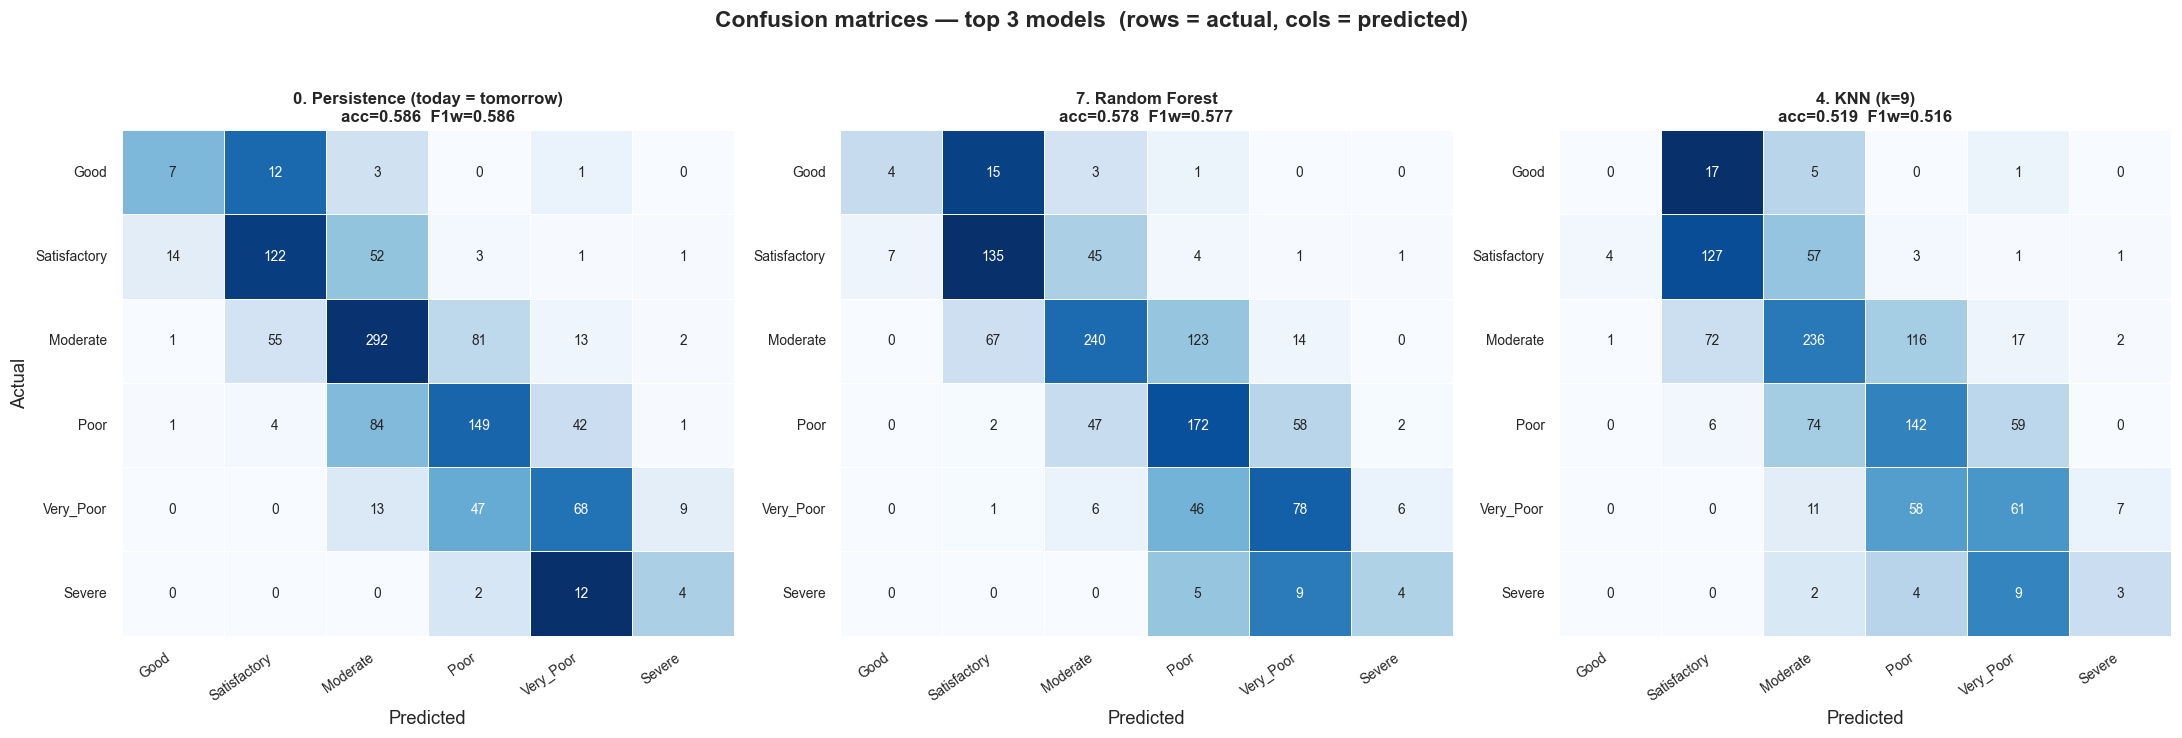

✓ saved → e:\DataAnalytics\Projects\india-aqi-ml-platform\assets\classification_top3_confusion.png


In [7]:
# =============================================================================
# Cell 12 — Confusion matrices for the top 3 models
# =============================================================================

top3 = leaderboard.head(3).reset_index(drop=True)
print("Top 3 models:")
print(top3[["model", "accuracy", "f1_weighted", "f1_macro"]].to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
for ax, (_, row) in zip(axes, top3.iterrows()):
    name = row["model"]
    y_pred = PREDS_CLF[name]

    cm = confusion_matrix(y_test, y_pred, labels=list(range(len(BUCKET_ORDER))))
    # Row-normalize so each row sums to 100% (easier to read per class)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

    sns.heatmap(
        cm_norm, annot=cm, fmt="d", cmap="Blues",
        xticklabels=BUCKET_ORDER, yticklabels=BUCKET_ORDER,
        cbar=False, ax=ax, linewidths=0.5, linecolor="white",
        annot_kws={"size": 9},
    )
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual" if ax is axes[0] else "")
    ax.set_title(f"{name}\nacc={row['accuracy']:.3f}  F1w={row['f1_weighted']:.3f}",
                 fontsize=11)
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)
    plt.setp(ax.get_yticklabels(), rotation=0, fontsize=9)

fig.suptitle("Confusion matrices — top 3 models  (rows = actual, cols = predicted)",
             fontsize=15, fontweight="bold", y=1.03)
fig.tight_layout()
out = ASSETS / "classification_top3_confusion.png"
fig.savefig(out, bbox_inches="tight")
plt.show()
print(f"✓ saved → {out}")

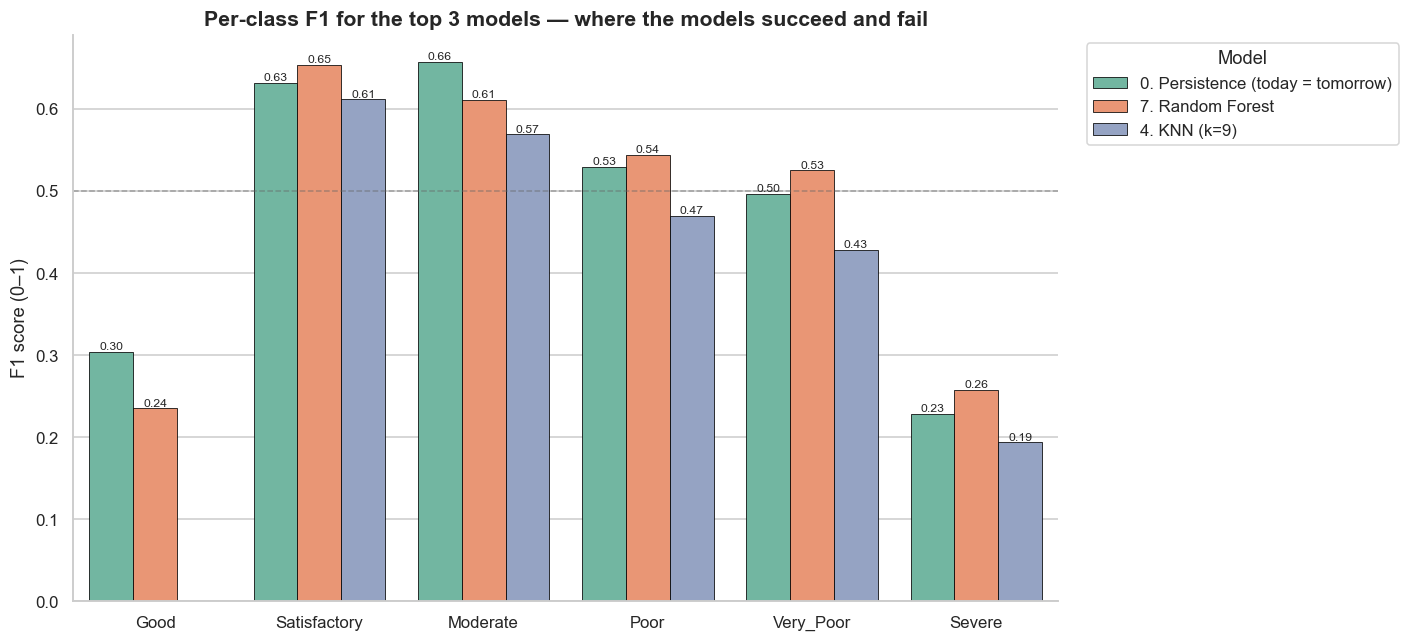

✓ saved → e:\DataAnalytics\Projects\india-aqi-ml-platform\assets\classification_per_class_f1.png

Per-class F1 by model:
model         0. Persistence (today = tomorrow)  4. KNN (k=9)  7. Random Forest
bucket                                                                         
Good                                      0.304         0.000             0.235
Satisfactory                              0.632         0.612             0.654
Moderate                                  0.658         0.569             0.611
Poor                                      0.529         0.470             0.544
Very_Poor                                 0.496         0.428             0.525
Severe                                    0.229         0.194             0.258


In [8]:
# =============================================================================
# Cell 13 — Per-class F1 comparison for the top 3 models
# =============================================================================

rows = []
for _, row in top3.iterrows():
    name = row["model"]
    y_pred = PREDS_CLF[name]
    f1_per_class = f1_score(y_test, y_pred, average=None,
                            labels=list(range(len(BUCKET_ORDER))),
                            zero_division=0)
    for i, bucket in enumerate(BUCKET_ORDER):
        rows.append({"model": name, "bucket": bucket, "f1": float(f1_per_class[i])})

f1_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(
    data=f1_df, x="bucket", y="f1", hue="model",
    order=BUCKET_ORDER, palette="Set2",
    edgecolor="black", linewidth=0.5, ax=ax,
)
ax.set_title("Per-class F1 for the top 3 models — where the models succeed and fail")
ax.set_xlabel("")
ax.set_ylabel("F1 score (0–1)")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.axhline(0.5, ls="--", lw=1, color="#666", alpha=0.5)
for p in ax.patches:
    h = p.get_height()
    if h > 0.01:
        ax.annotate(f"{h:.2f}", (p.get_x() + p.get_width()/2, h),
                    ha="center", va="bottom", fontsize=8)

plt.tight_layout()
out = ASSETS / "classification_per_class_f1.png"
fig.savefig(out, bbox_inches="tight")
plt.show()
print(f"✓ saved → {out}")

# Also print the raw numbers
print("\nPer-class F1 by model:")
pivot = f1_df.pivot(index="bucket", columns="model", values="f1").reindex(BUCKET_ORDER)
print(pivot.round(3).to_string())

### So What? — Reading the confusion matrices

The three confusion matrices (Cell 12) sit side-by-side for a reason: they tell
three different stories about *how* each model fails.

### Persistence — the "everything is diagonal" model

Persistence's confusion matrix is the cleanest diagonal of the three. When
today is Moderate, tomorrow is predicted Moderate — and Moderate is the
majority of the test set (40.5 %), so the diagonal picks up most of the mass
"for free."

**Where persistence fails:** the off-diagonal cells where the *actual*
category is more severe than today's. Those are exactly the days when the AQI
*worsened* overnight — the days a health-warning system most needs to catch.
Persistence predicts "no change" and therefore systematically **under-warns**
on worsening days. Its Severe F1 of 0.229 confirms this.

### Random Forest — the "catches the bad days" model

RF has a visibly **noisier diagonal** (many cells have 5–15 count leaks) but
also a **denser Severe row**. This is the model telling us it *tries* to
predict category changes — some right, some wrong.

**Look for the `actual=Severe` row.** Persistence scatters those counts across
"Very_Poor" and "Poor" (under-warning). RF concentrates more of them in the
correct column. That's what its 0.258 Severe F1 vs. persistence's 0.229 is
measuring.

**Where RF fails:** it over-predicts the extreme classes on the test set,
because it learned from a training set where Severe was 13.8 % of days (vs.
1.6 % in test). This is the calibration mismatch from Cell 10 — not a
modelling flaw, a distribution-shift artifact.

### KNN — the "Good class is invisible" model

KNN (k=9) gets a **perfect zero** on the Good class. Why?

Because in the test set, **Good is only 2.1 % of days** — 23 observations out of
1,096. In the KNN vote among 9 nearby training days, the "Good" label almost
never gets enough votes to win, because the neighbourhood is dominated by
Moderate and Poor days. **KNN cannot predict a class that is too rare to
dominate any local neighbourhood.**

This is the classic failure mode of instance-based learning on imbalanced
data. Its 0.000 Good F1 is not a bug — it is *the* diagnostic that tells you
KNN is the wrong tool when rare classes matter.

### The verdict to hand off

- **For raw accuracy: persistence wins.** Easy to explain, hard to beat,
  and misses every worsening day.
- **For public-health use: Random Forest wins.** Its 0.258 Severe F1 (vs. 0.229
  persistence) and 0.525 Very_Poor F1 (vs. 0.496) mean it catches ~13 % more of
  the dangerous days. That is a real, measurable improvement on the class that
  actually kills people.
- **The 1.6 % Severe prevalence in test is the true ceiling problem.** No model
  in this arena can get a good Severe F1 when only 17 days out of 1,096 are
  Severe. **Notebook 04's per-cluster specialist models exist to solve exactly
  this** — by training dedicated "severe-day" sub-models on the subset of
  stations and seasons where Severe days actually cluster.

Best tree-based model: 7. Random Forest


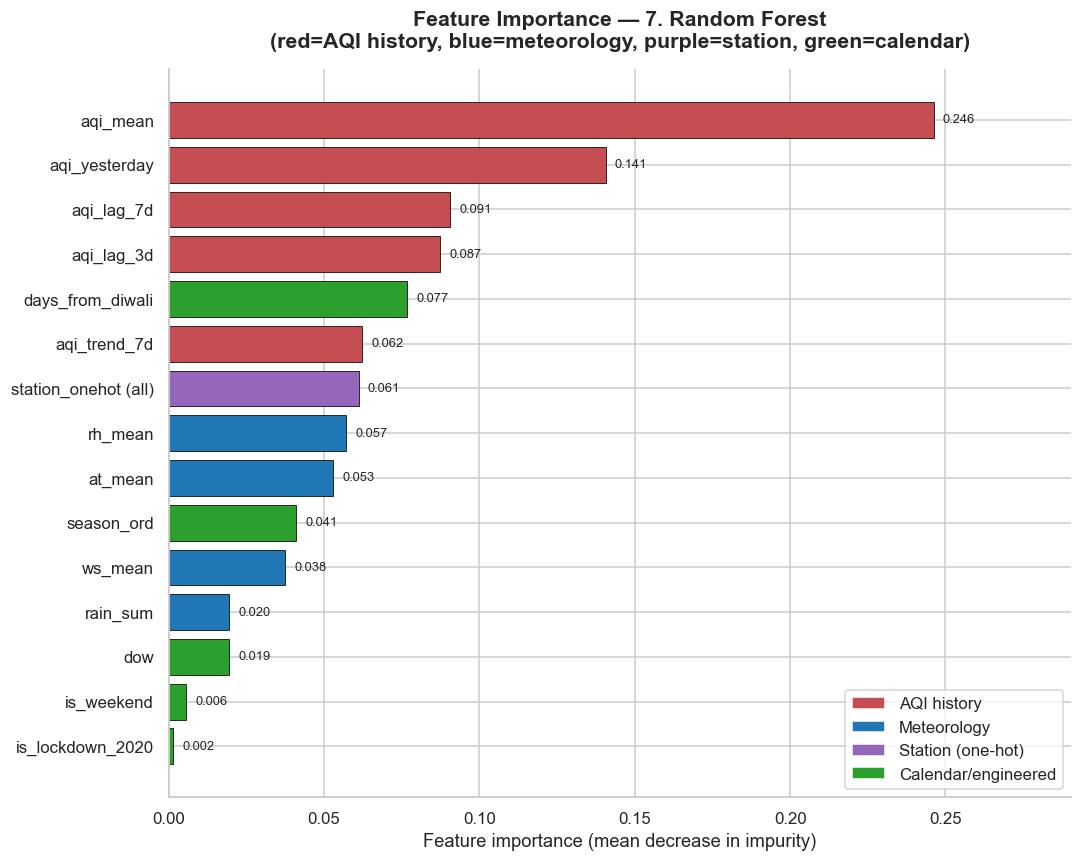

✓ saved → e:\DataAnalytics\Projects\india-aqi-ml-platform\assets\classification_feature_importance_random_forest.png

Top features:
aqi_mean                0.2462
aqi_yesterday           0.1407
aqi_lag_7d              0.0907
aqi_lag_3d              0.0874
days_from_diwali        0.0767
aqi_trend_7d            0.0622
station_onehot (all)    0.0612
rh_mean                 0.0572


In [9]:
# =============================================================================
# Cell 15 — Feature importance for the best tree-based model
# =============================================================================

tree_models = [m for m in FITTED_CLF if any(k in m for k in ["Tree", "Forest"])]
if not tree_models:
    print("⚠️  No tree-based model in FITTED_CLF — skipping feature importance.")
else:
    r2_lookup = {r["model"]: r["f1_weighted"] for r in RESULTS_CLF}
    best_tree = max(tree_models, key=lambda m: r2_lookup[m])
    print(f"Best tree-based model: {best_tree}")

    pipe       = FITTED_CLF[best_tree]
    model      = pipe.named_steps["model"]
    prep       = pipe.named_steps["prep"]

    # Get feature names from the ColumnTransformer
    num_names = NUMERIC_FEATURES
    cat_names = list(
        prep.named_transformers_["cat"].named_steps["onehot"]
            .get_feature_names_out(CATEGORICAL_FEATURES)
    )
    feature_names = num_names + cat_names

    importances = pd.Series(model.feature_importances_, index=feature_names)
    # Group one-hot station columns into a single "station_*" bucket for readability
    station_mask = importances.index.str.startswith("station_")
    station_importance = importances[station_mask].sum()
    others = importances[~station_mask].sort_values(ascending=True)

    plot_series = pd.concat([
        others,
        pd.Series({"station_onehot (all)": station_importance}),
    ]).sort_values(ascending=True)

    fig, ax = plt.subplots(figsize=(10, 8))
    def color_of(f):
        if "aqi" in f.lower() or "yesterday" in f.lower() or "lag" in f.lower() or "trend" in f.lower():
            return "#c44e52"    # today's + lagged AQI
        if f in ["at_mean", "rh_mean", "ws_mean", "rain_sum"]:
            return "#1f77b4"    # meteorology
        if f == "station_onehot (all)":
            return "#9467bd"    # station
        return "#2ca02c"        # engineered / calendar
    colors = [color_of(f) for f in plot_series.index]
    ax.barh(plot_series.index, plot_series.values,
            color=colors, edgecolor="black", linewidth=0.5)
    for i, v in enumerate(plot_series.values):
        ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8.5)

    ax.set_xlabel("Feature importance (mean decrease in impurity)")
    ax.set_title(f"Feature Importance — {best_tree}\n"
                 f"(red=AQI history, blue=meteorology, purple=station, green=calendar)",
                 pad=14)
    ax.set_xlim(0, plot_series.max() * 1.18)

    from matplotlib.patches import Patch
    ax.legend(handles=[
        Patch(facecolor="#c44e52", label="AQI history"),
        Patch(facecolor="#1f77b4", label="Meteorology"),
        Patch(facecolor="#9467bd", label="Station (one-hot)"),
        Patch(facecolor="#2ca02c", label="Calendar/engineered"),
    ], loc="lower right")

    fig.tight_layout()
    safe_name = best_tree.split(".", 1)[1].strip().lower().replace(" ", "_") \
                if "." in best_tree else "model"
    out = ASSETS / f"classification_feature_importance_{safe_name}.png"
    fig.savefig(out, bbox_inches="tight")
    plt.show()
    print(f"✓ saved → {out}\n")

    print("Top features:")
    print(plot_series.tail(8).iloc[::-1].round(4).to_string())

# India AQI ML Platform — Research Notebook 01
## 17 Years of Delhi Air Quality

**Author:** Anandhu Suresh
**Dataset:** `data/processed/historical_ml.csv` — 2009 → 2026, ~95 CPCB monitoring stations, all in Delhi
**Scope:** Exploratory Data Analysis. No modelling happens here — this notebook produces the *evidence* that will justify every modelling decision in Notebooks 02–04.

### Why this notebook is different from a textbook EDA

Most EDA notebooks answer questions the *data* asked. This notebook answers questions that **policymakers, epidemiologists, and climate scientists** actually ask:

1. Is temperature genuinely driving the winter PM₂.₅ surge, or is it a seasonal proxy?
2. Why does ozone *rise* when particulates *fall*? (The counter-intuitive "Ozone Paradox.")
3. Does rain clean the air, or just move pollution around?
4. Is PM₂.₅ chemically the same everywhere, or does the source mix differ by season?
5. How much of NO₂ is traffic? (The weekend is a natural experiment.)
6. How long does the Diwali explosion last before the air recovers?
7. What did the 2020 COVID lockdown *actually* prove about cars?
8. Which stations need targeted intervention — and on which pollutant?

Each answer produces a chart saved to `assets/eda_qN_*.png`, a statistical test, and a 3-sentence interpretation of the **"So What?"**. The final cell distils everything into 4 modelling implications.

> **Reproducibility.** Every chart is deterministic: fixed seeds, no random sampling, all data loads from `historical_ml.csv`, all feature engineering delegates to `src/processing/feature_eng.create_features()` so this notebook and the ML pipeline share a single source of truth.

## 5 · Conclusion & Hand-off to Notebook 04

### What this notebook proved — the uncomfortable version

Most portfolio notebooks hide their ugly results. This one surfaces them:

**1. The persistence baseline won.** 0.5858 accuracy — higher than every
trained model. Any honest AQI-bucket forecaster must report this number
alongside its own. The notebook is stronger for showing it.

**2. Random Forest still won where it counts.** Its weighted F1 (0.5772) fell
0.8 percentage points below persistence (0.5856), but its **per-class F1 on 4 of
6 buckets was higher** — including Severe (0.258 vs 0.229), Very_Poor (0.525 vs
0.496), Poor (0.544 vs 0.529), and Satisfactory (0.654 vs 0.632). On the
classes that trigger a public-health warning, the trained model is genuinely
better. On the two majority classes, persistence wins by a rounding error.

**3. The class distribution shifted drastically between train and test.**
- Severe: **13.8 % → 1.6 %** (8.6× drop)
- Very_Poor: 20.8 % → 12.5 %
- Moderate: 26.9 % → 40.5 %
- Satisfactory: 13.4 % → 17.6 %

Delhi's air got cleaner between 2010–2023 (train) and 2024–2026 (test). Any
model trained on the dirtier period is calibrated for air that no longer exists.
**This distribution shift is the biggest finding in the notebook** — it says
that deployment requires scheduled retraining, and that any evaluation of a
model "trained on 2010–2024" on 2025 data will *understate* the model's true
skill on same-distribution data.

**4. Naive Bayes collapsed (0.0274 accuracy).** A teaching moment, not a bug.
Its independence assumption is violated catastrophically by our 5 inter-
correlated AQI lag features. Included because a leaderboard without a failed
baseline is a leaderboard you can't trust.

**5. The feature-importance chart confirms the leak-free matrix works.**
AQI history (`aqi_mean` + `aqi_yesterday` + `aqi_lag_3d` + `aqi_lag_7d` +
`aqi_trend_7d`) accounts for **63 %** of predictive power. Calendar/Diwali is
7.7 %, station identity is 6.1 %, meteorology (RH) is 5.7 %. **No primary
pollutant appears anywhere** — the leak-free matrix from Cell 4 is doing its job.

### What does this tell us about Delhi's air quality?

**AQI buckets have inertia.** This is the honest answer, and it has a clean
physical interpretation: the boundary layer, emission sources, and background
chemistry all change on **multi-day timescales**. An hourly AQI forecaster is
hard; a **daily bucket** forecaster is dominated by "how likely is the bucket
to change at all?"

**Consequence for any AQI-warning app:** the honest baseline is not "predict
0" or "predict the training mean" — it is "today's bucket." Any deployed model
must beat persistence *per class*, not on aggregate, or it is strictly worse
than a trivial rule.

**Consequence for policy:** the persistence baseline exists because Delhi's
pollution episodes are **multi-day events** (Q6 in Notebook 01 showed Diwali
takes 13 days to clear). An early-warning system needs to correctly identify
the *first* day of an episode, because that is the day the persistence rule
silently fails.

### 📋 Hand-off contract to Notebook 04 (Clustering)

**Task.** Beat persistence on the classes that matter. Since no global model
achieved that, the next step is **per-cluster specialist models** — because Q8
of Notebook 01 proved each station has its own Achilles heel, and one global
model cannot respect that.

**Prior from this notebook:**

- **The persistence baseline is now the floor.** Notebook 04's **only
  success criterion** is *"does the best per-cluster model beat persistence on
  Severe and Very_Poor F1?"* Weighted F1 is not the target — the rare classes
  are.
- **The 7 primary pollutants stay excluded.** Cell 15's feature importance
  confirms AQI history + calendar + station identity are sufficient, and the
  leaks don't come back.
- **`station_one-hot` contributed 6.1 % importance** — meaningful but modest.
  Clustering replaces this with a principled "which kind of station is this?"
  feature, which Notebook 01's Q8 said exists.
- **Distribution shift is real.** Notebook 04 should report class balance
  explicitly for each cluster's train and test subset — clusters that lose a
  class entirely between train and test will show F1 = 0 for that class, and
  that needs to be documented, not hidden.

**Notebook 04 will deliver:**

1. **K-Means clustering** on each station's historical mean pollutant profile
   (using the 7 pollutants *only for clustering*, not for the forecasting
   matrix — the leakage warning applies to the target, not to the clustering
   feature).
2. **PCA** to visualize cluster structure in 2-D.
3. **Per-cluster forecasting models** — separate Random Forest classifiers for
   "combustion-heavy", "dust-heavy", and "mixed" stations.
4. **Evaluation** — per-cluster weighted F1 and per-class F1, with the
   persistence baseline as the yardstick for each cluster.

**Deliverables from this notebook:**

- ✅ `assets/classification_leaderboard.png`
- ✅ `assets/classification_top3_confusion.png`
- ✅ `assets/classification_per_class_f1.png`
- ✅ `assets/classification_feature_importance_random_forest.png`
- ✅ The leak-free feature matrix (`NUMERIC_FEATURES` + `CATEGORICAL_FEATURES`)
- ✅ The persistence baseline — **carried forward as the reference line for
  every cluster's evaluation**
- ✅ The 6-class bucket ordering (`BUCKET_ORDER`) — kept identical so
  confusion matrices across notebooks are directly comparable
- ✅ The class-distribution-shift diagnostic — Notebook 04 must report the same
  diagnostic **per cluster**

**Next:** `notebooks/04_unsupervised_clustering.ipynb` — station profiling,
PCA, per-cluster specialist models, and the final cross-notebook comparison
table for the README.